In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## YOLO11 via Ultralytics

In [ ]:
%pip install "ultralytics<=8.3.40" supervision roboflow
# prevent ultralytics from tracking your activity
!yolo settings sync=False
import ultralytics
ultralytics.checks()

Ultralytics 8.3.40 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


## Fine-tune YOLO11 on custom dataset

In [ ]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata
from roboflow import Roboflow

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

workspace = rf.workspace("liangdianzhong")
project = rf.workspace("full-stack-data-science").project("pothhole-detection")
version = project.version(1)
dataset = version.download("yolov11")

/content/datasets
loading Roboflow workspace...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to pothhole-detection-1 in yolov11:: 100%|██████████| 1335/1335 [00:00<00:00, 10646.45it/s]


## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo11s.pt data={dataset.location}/data.yaml epochs=10 imgsz=640 plots=True

/content
100% 18.4M/18.4M [00:00<00:00, 139MB/s] 
New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolo11s.pt, data=/content/datasets/pothhole-detection-1/data.yaml, epochs=10, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=Fal

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml					    results.png
confusion_matrix_normalized.png			    train_batch0.jpg
confusion_matrix.png				    train_batch1.jpg
events.out.tfevents.1791710115.4d1f5cd5b4b8.2757.0  train_batch2.jpg
F1_curve.png					    val_batch0_labels.jpg
labels_correlogram.jpg				    val_batch0_pred.jpg
labels.jpg					    val_batch1_labels.jpg
P_curve.png					    val_batch1_pred.jpg
PR_curve.png					    val_batch2_labels.jpg
R_curve.png					    val_batch2_pred.jpg
results.csv					    weights


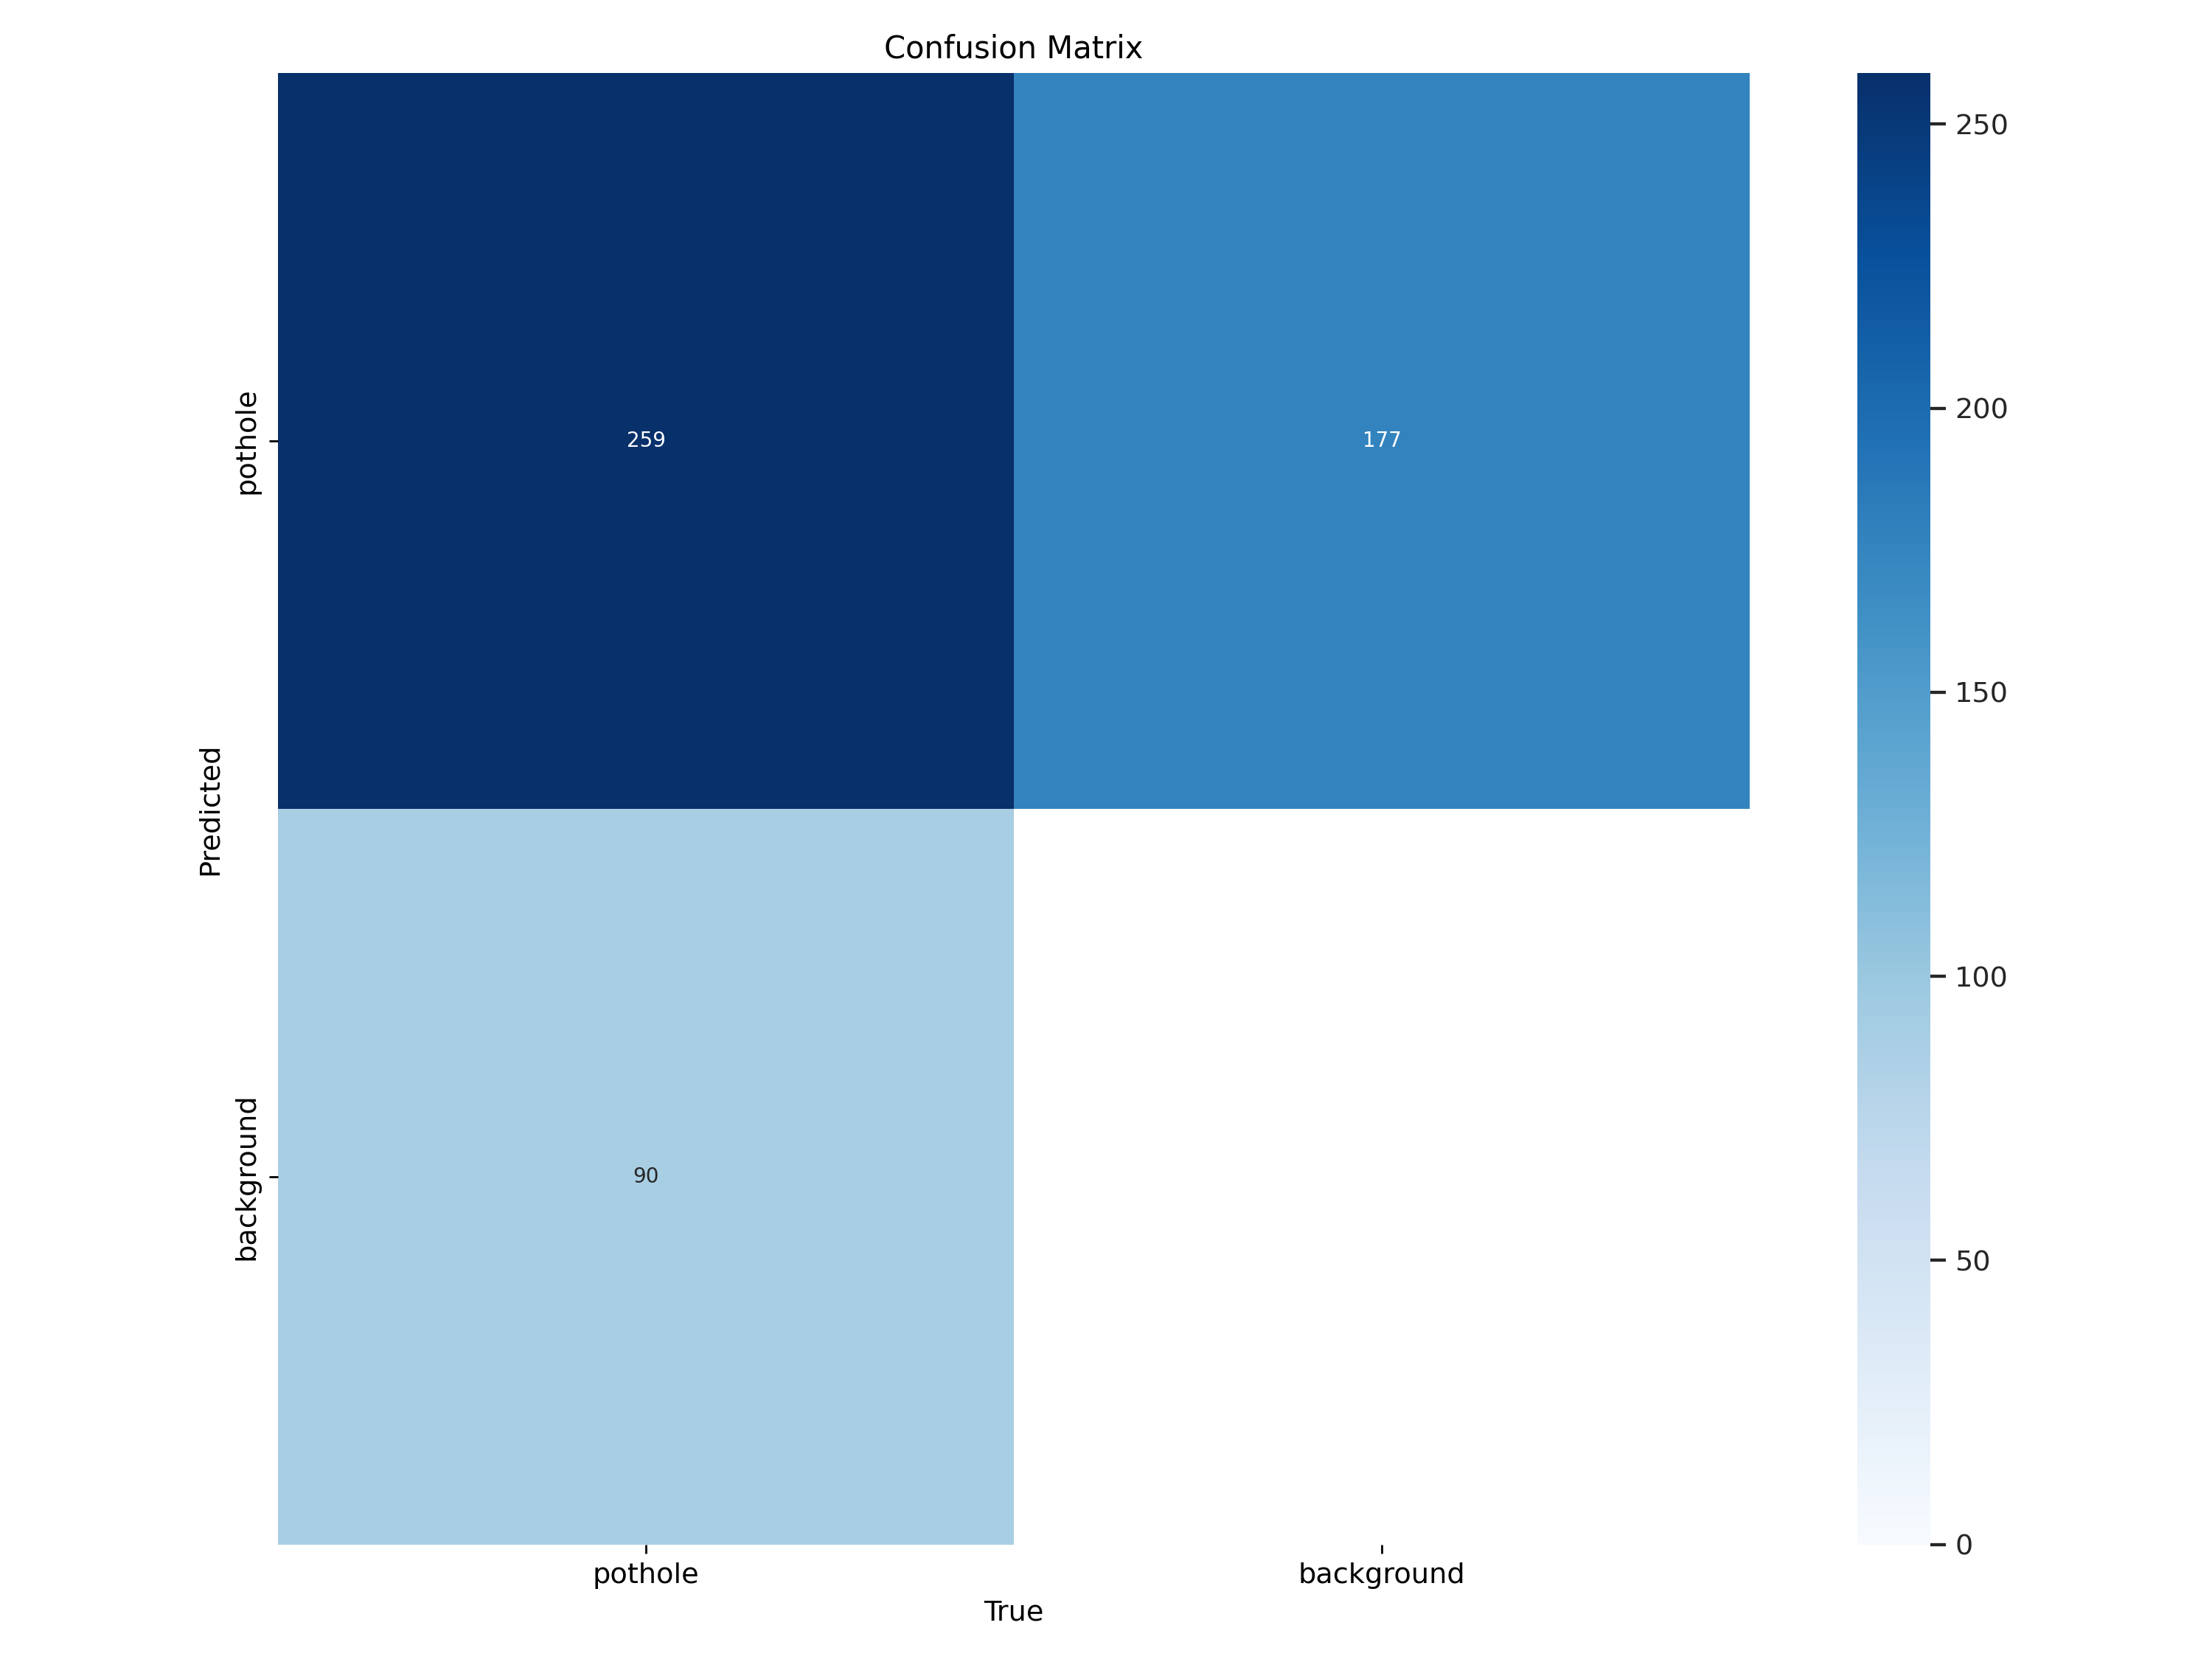

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

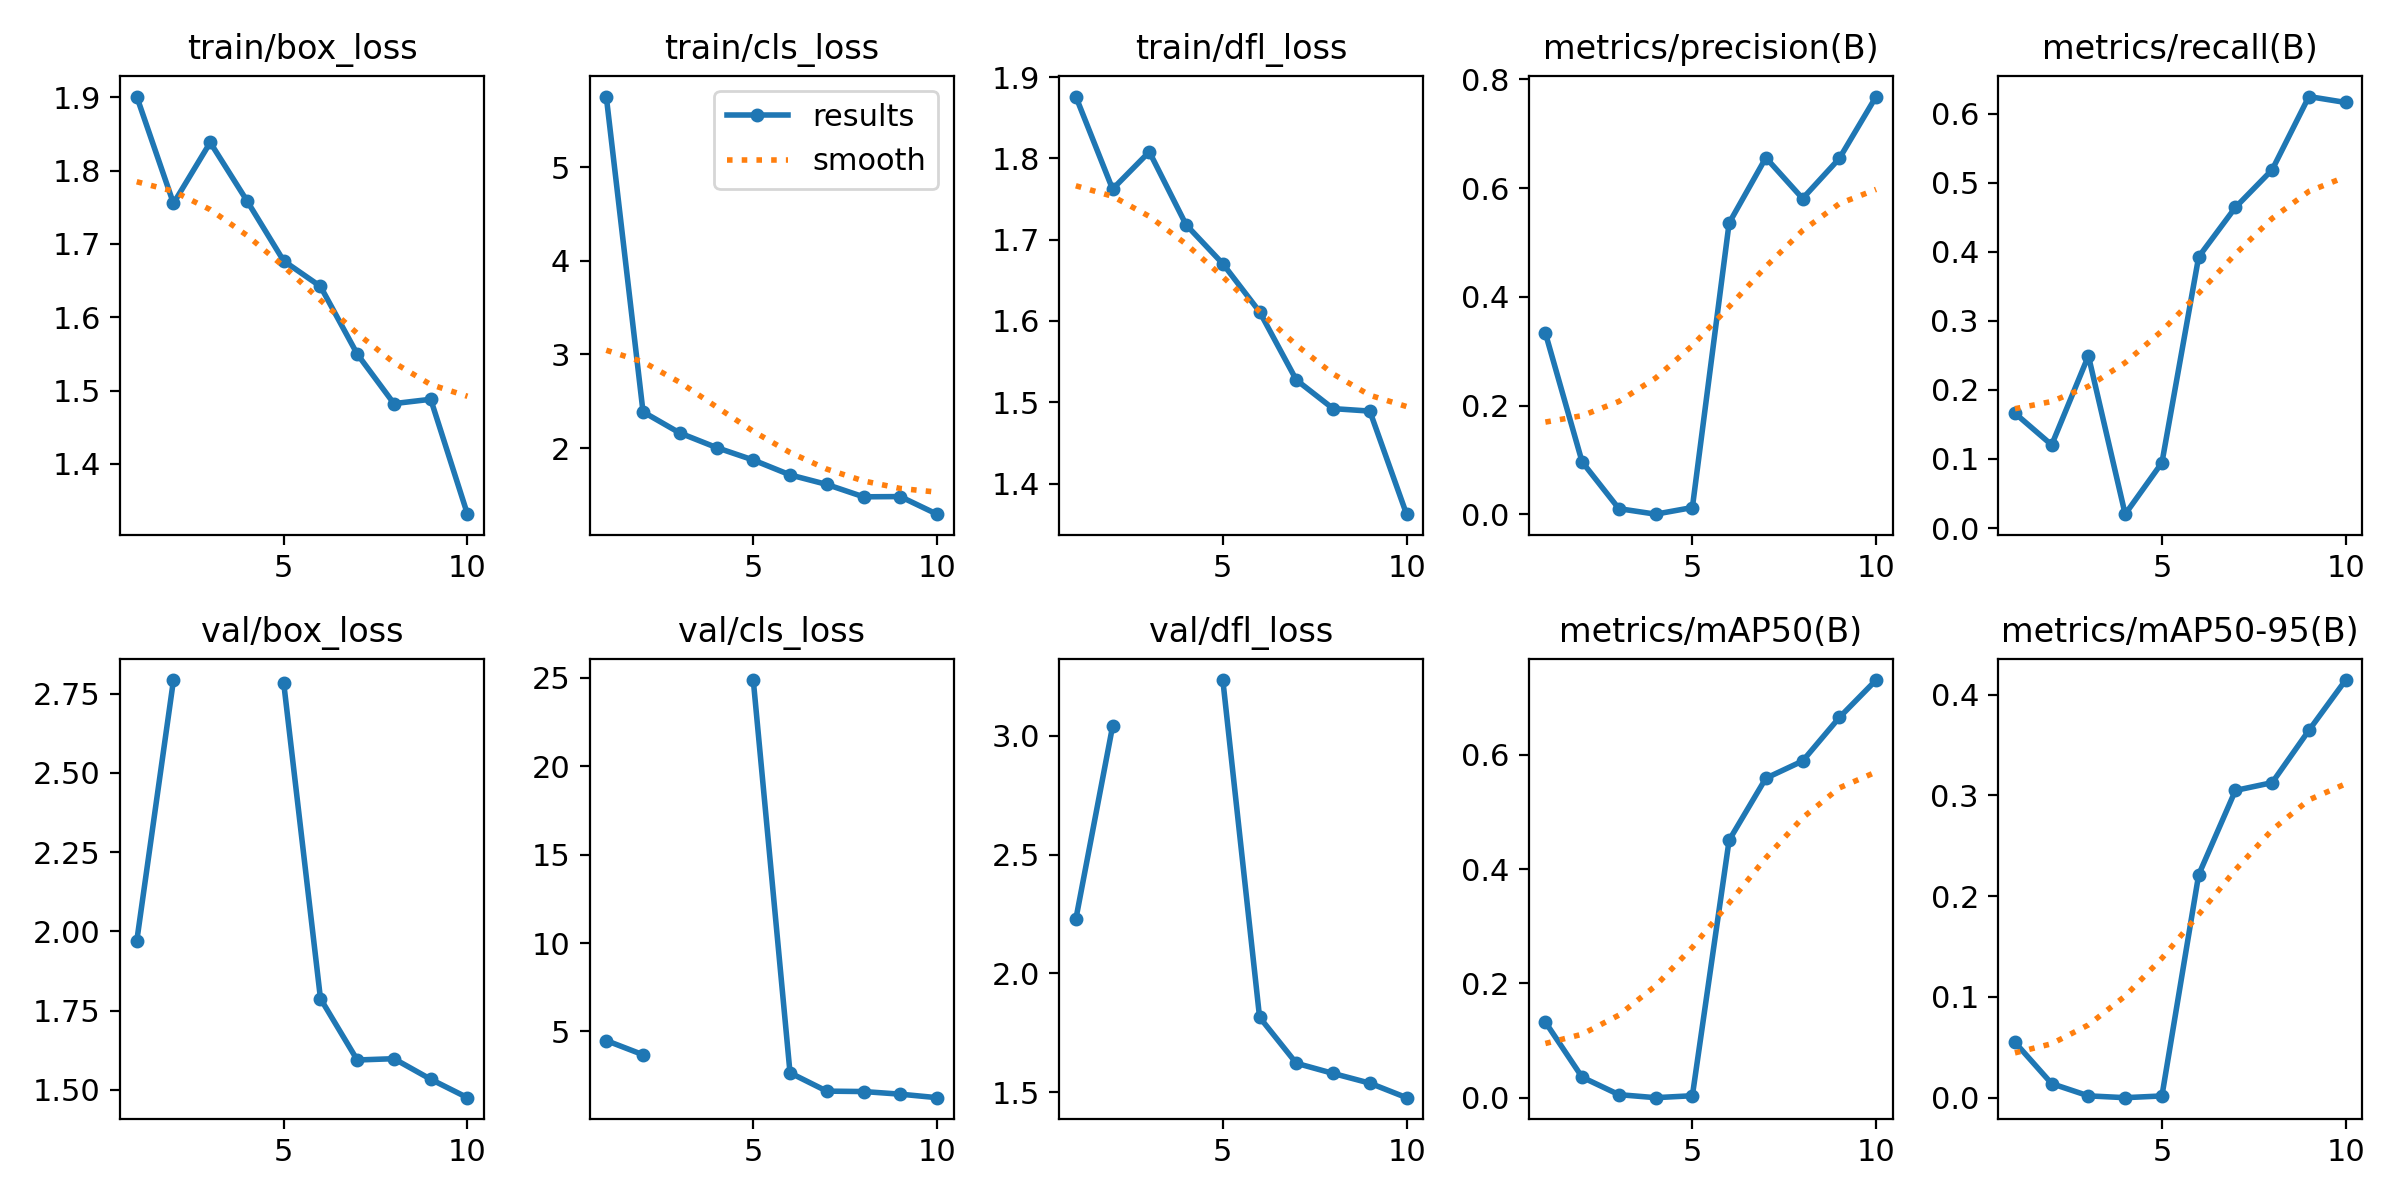

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/results.png', width=600)

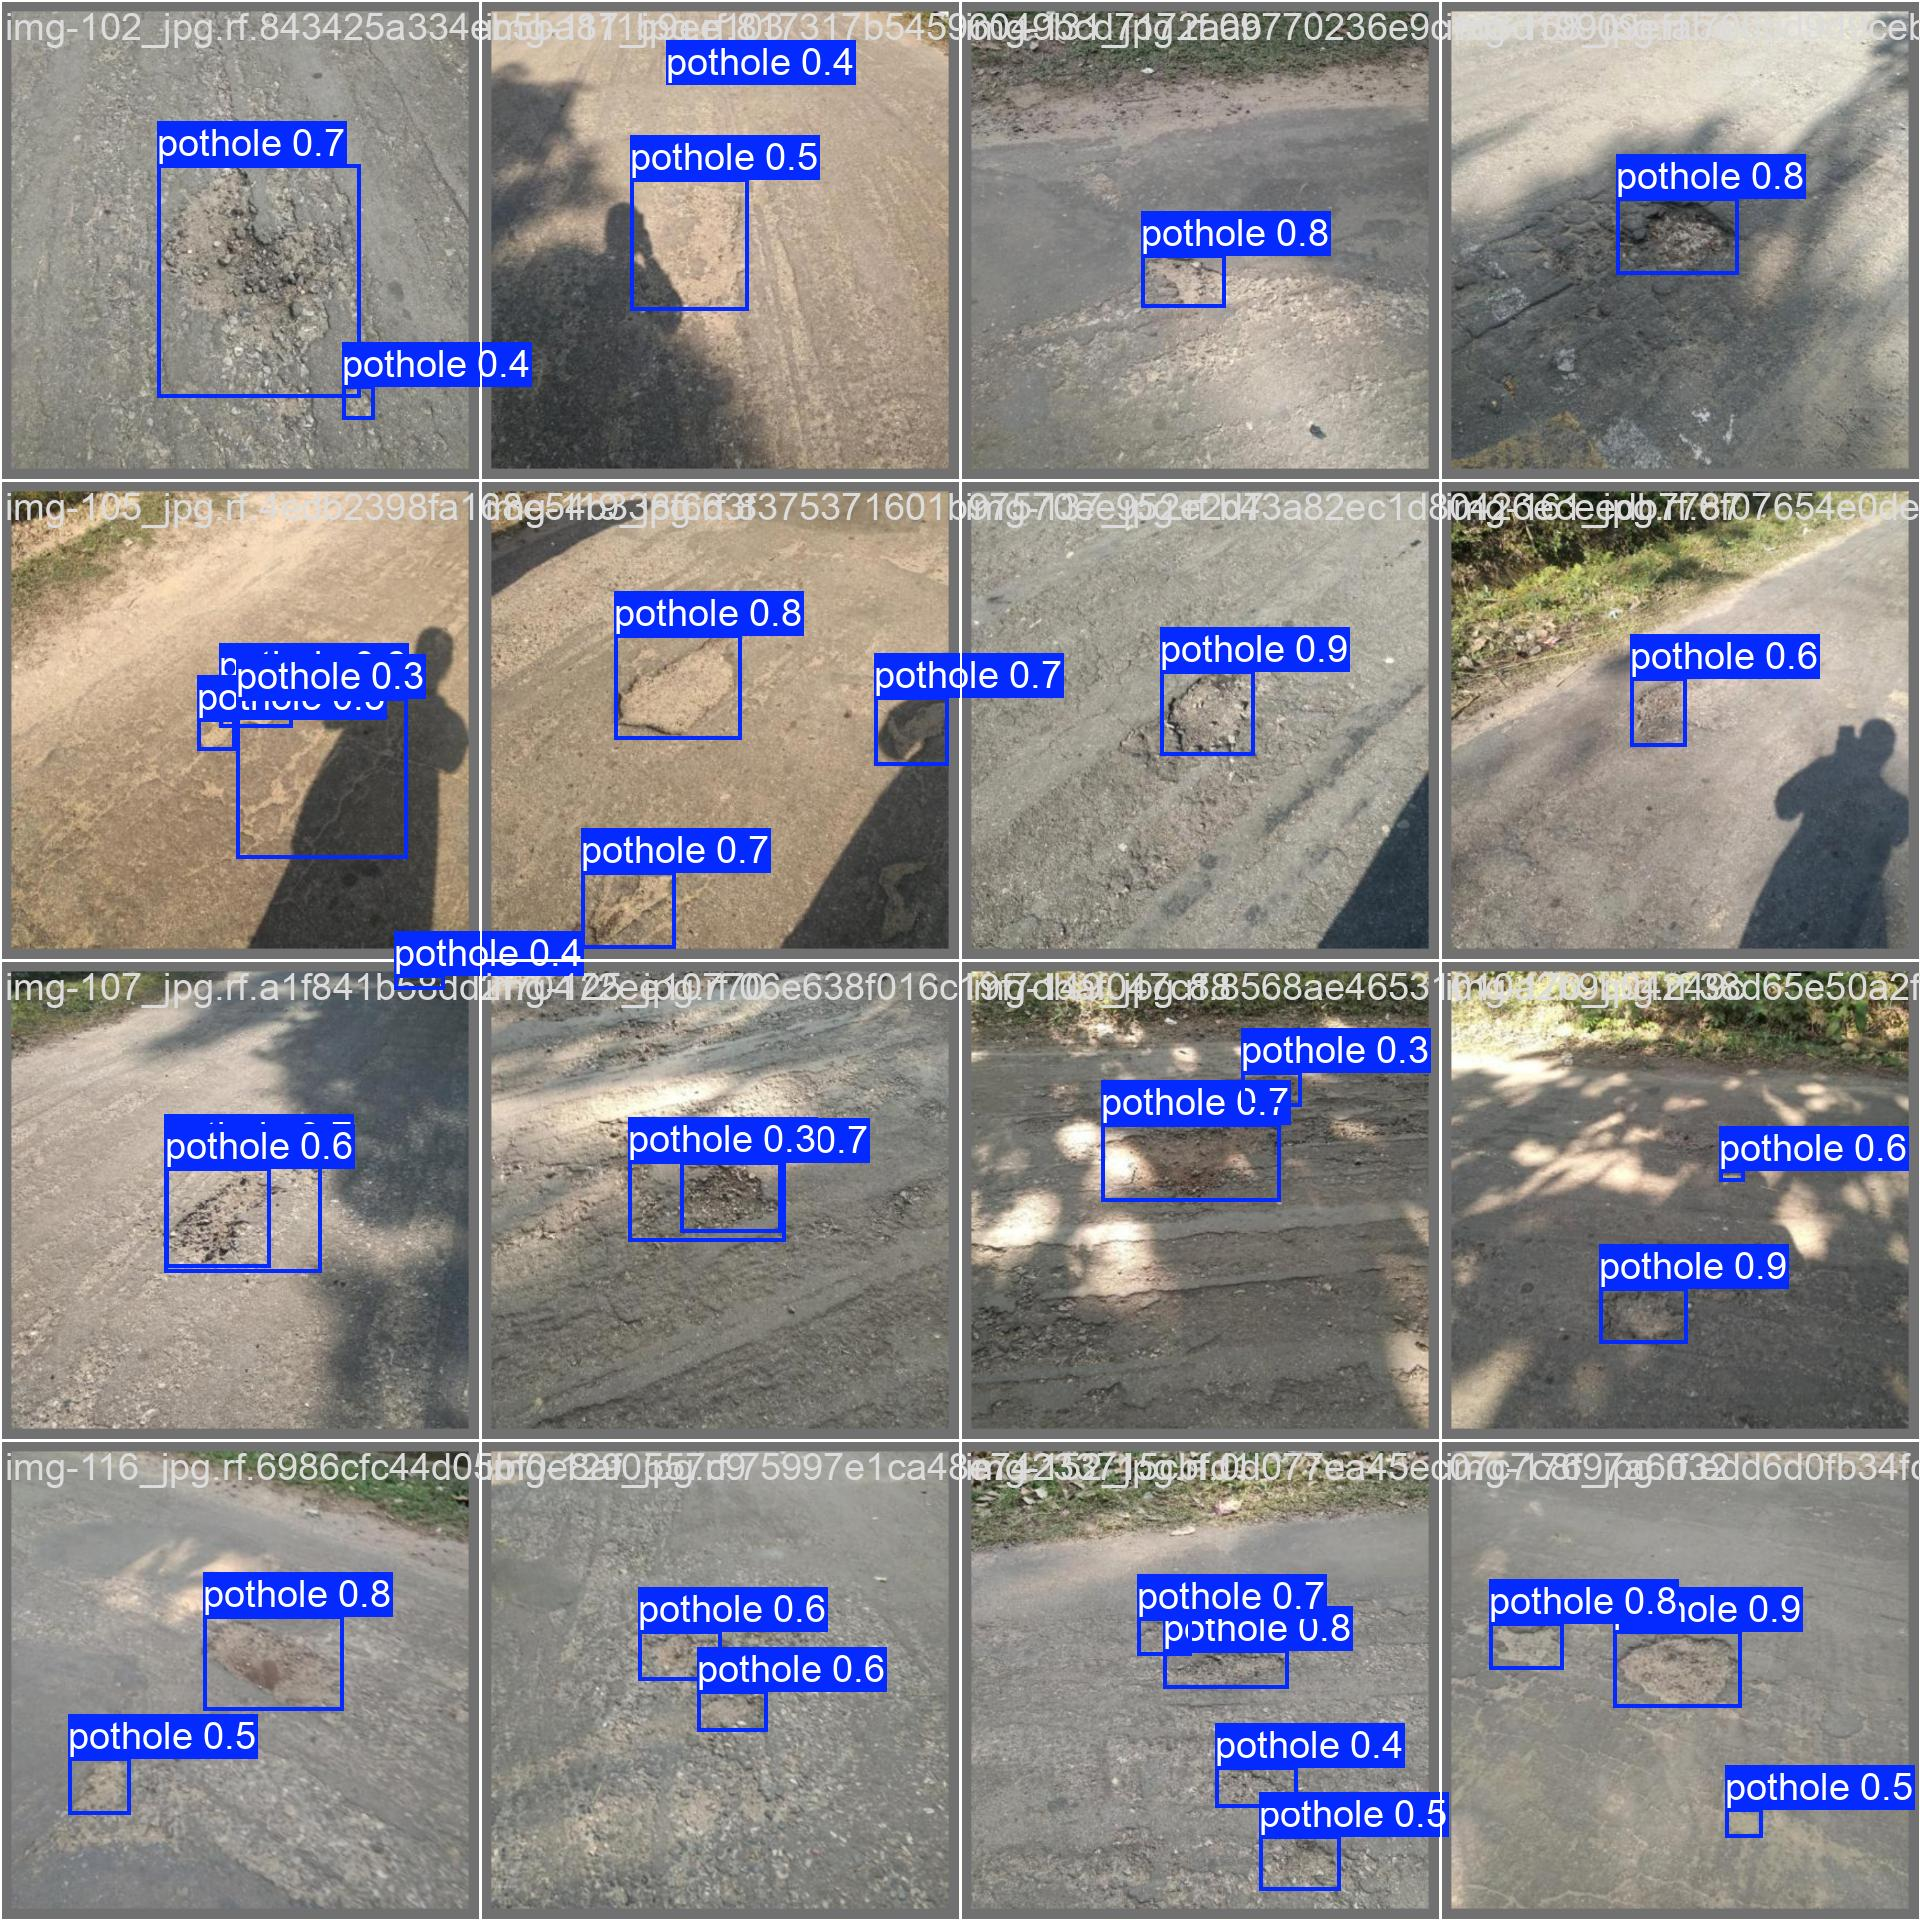

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [ ]:
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.3.40 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 238 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs
val: Scanning /content/datasets/pothhole-detection-1/valid/labels.cache... 133 images, 0 backgrounds, 0 corrupt: 100% 133/133 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 9/9 [00:03<00:00,  2.46it/s]
                   all        133        349      0.764      0.614      0.725      0.414
Speed: 2.5ms preprocess, 12.0ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


## Inference with custom model

In [ ]:
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

Ultralytics 8.3.40 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 238 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs

image 1/67 /content/datasets/pothhole-detection-1/test/images/img-103_jpg.rf.7aa7538d125561d19e2b711c900188f2.jpg: 640x640 1 pothole, 24.1ms
image 2/67 /content/datasets/pothhole-detection-1/test/images/img-121_jpg.rf.2aabe362fe8f51ebaa84df79b1ba50b2.jpg: 640x640 2 potholes, 24.1ms
image 3/67 /content/datasets/pothhole-detection-1/test/images/img-123_jpg.rf.6683b3a4bdf109fda78ce7e2dc455720.jpg: 640x640 1 pothole, 24.1ms
image 4/67 /content/datasets/pothhole-detection-1/test/images/img-12_jpg.rf.5fe3b761b5a82eed34460a24058bc787.jpg: 640x640 2 potholes, 24.1ms
image 5/67 /content/datasets/pothhole-detection-1/test/images/img-140_jpg.rf.19c21c5514be04284ffbc7e456d8be0f.jpg: 640x640 4 potholes, 24.1ms
image 6/67 /content/datasets/pothhole-detection-1/test/images/img-162_jpg.rf.d61d95ab51ec7f3d3dfea0930c44a0e4.jpg: 640x640 1 

**NOTE:** Let's take a look at few results.

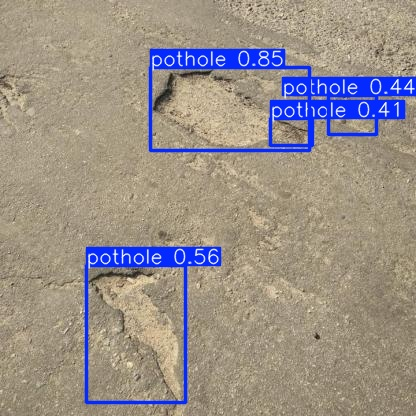

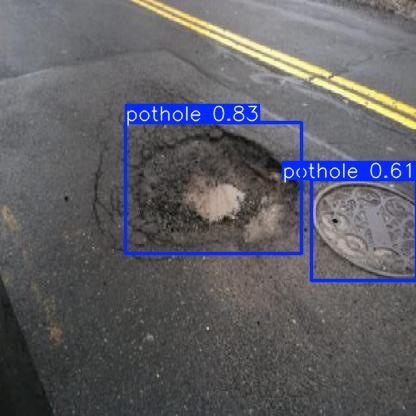

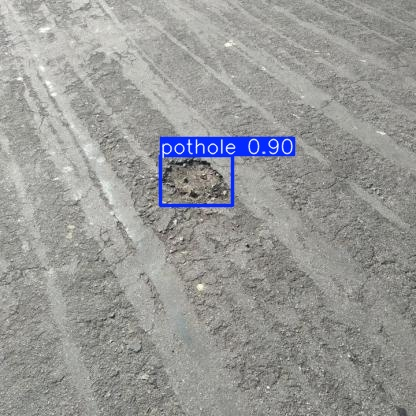

In [ ]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob(f'{HOME}/runs/detect/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[:3]:
    display(IPyImage(filename=img, width=600))
    print("\n")

### Test a New Image from the Web

Use your fine-tuned model weights to run inference on any image from the internet. Just replace the URL below with your own image URL.


0: 384x640 2 potholes, 48.7ms
Speed: 1.9ms preprocess, 48.7ms inference, 49.9ms postprocess per image at shape (1, 3, 384, 640)


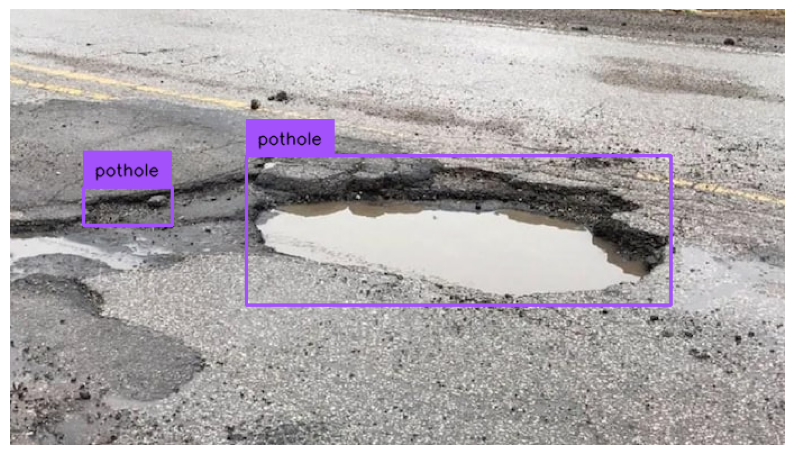

In [ ]:
from ultralytics import YOLO
from PIL import Image
import requests
import supervision as sv

# 1. Load your fine-tuned model
custom_model = YOLO(f'{HOME}/runs/detect/train/weights/best.pt')

# 2. Provide the URL of the image you want to test
image_url = 'https://akm-img-a-in.tosshub.com/indiatoday/images/story/202508/potholes-in-mumbai-171323137-16x9.png?VersionId=UBfxTKM.OfYh1q09m86JBmeZzaheAzn0&size=690:388' # Example image

# 3. Download and open the image
test_image = Image.open(requests.get(image_url, stream=True).raw)

# 4. Perform prediction
results = custom_model.predict(test_image, conf=0.25)[0]

# 5. Convert to Supervision detections and annotate
detections = sv.Detections.from_ultralytics(results)

box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator(text_color=sv.Color.BLACK)

annotated_test_image = test_image.copy()
annotated_test_image = box_annotator.annotate(annotated_test_image, detections=detections)
annotated_test_image = label_annotator.annotate(annotated_test_image, detections=detections)

# 6. Display the result
sv.plot_image(annotated_test_image, size=(10, 10))